# viz of gprofiler

i'm including all seeds, even the ones that are in the global ppi, as part of seeds - since if they've made it into the dm theyve made it into the dm - run august 4

In [1]:
pwd()

'/lisc/home/user/gerardursin/multiplex'

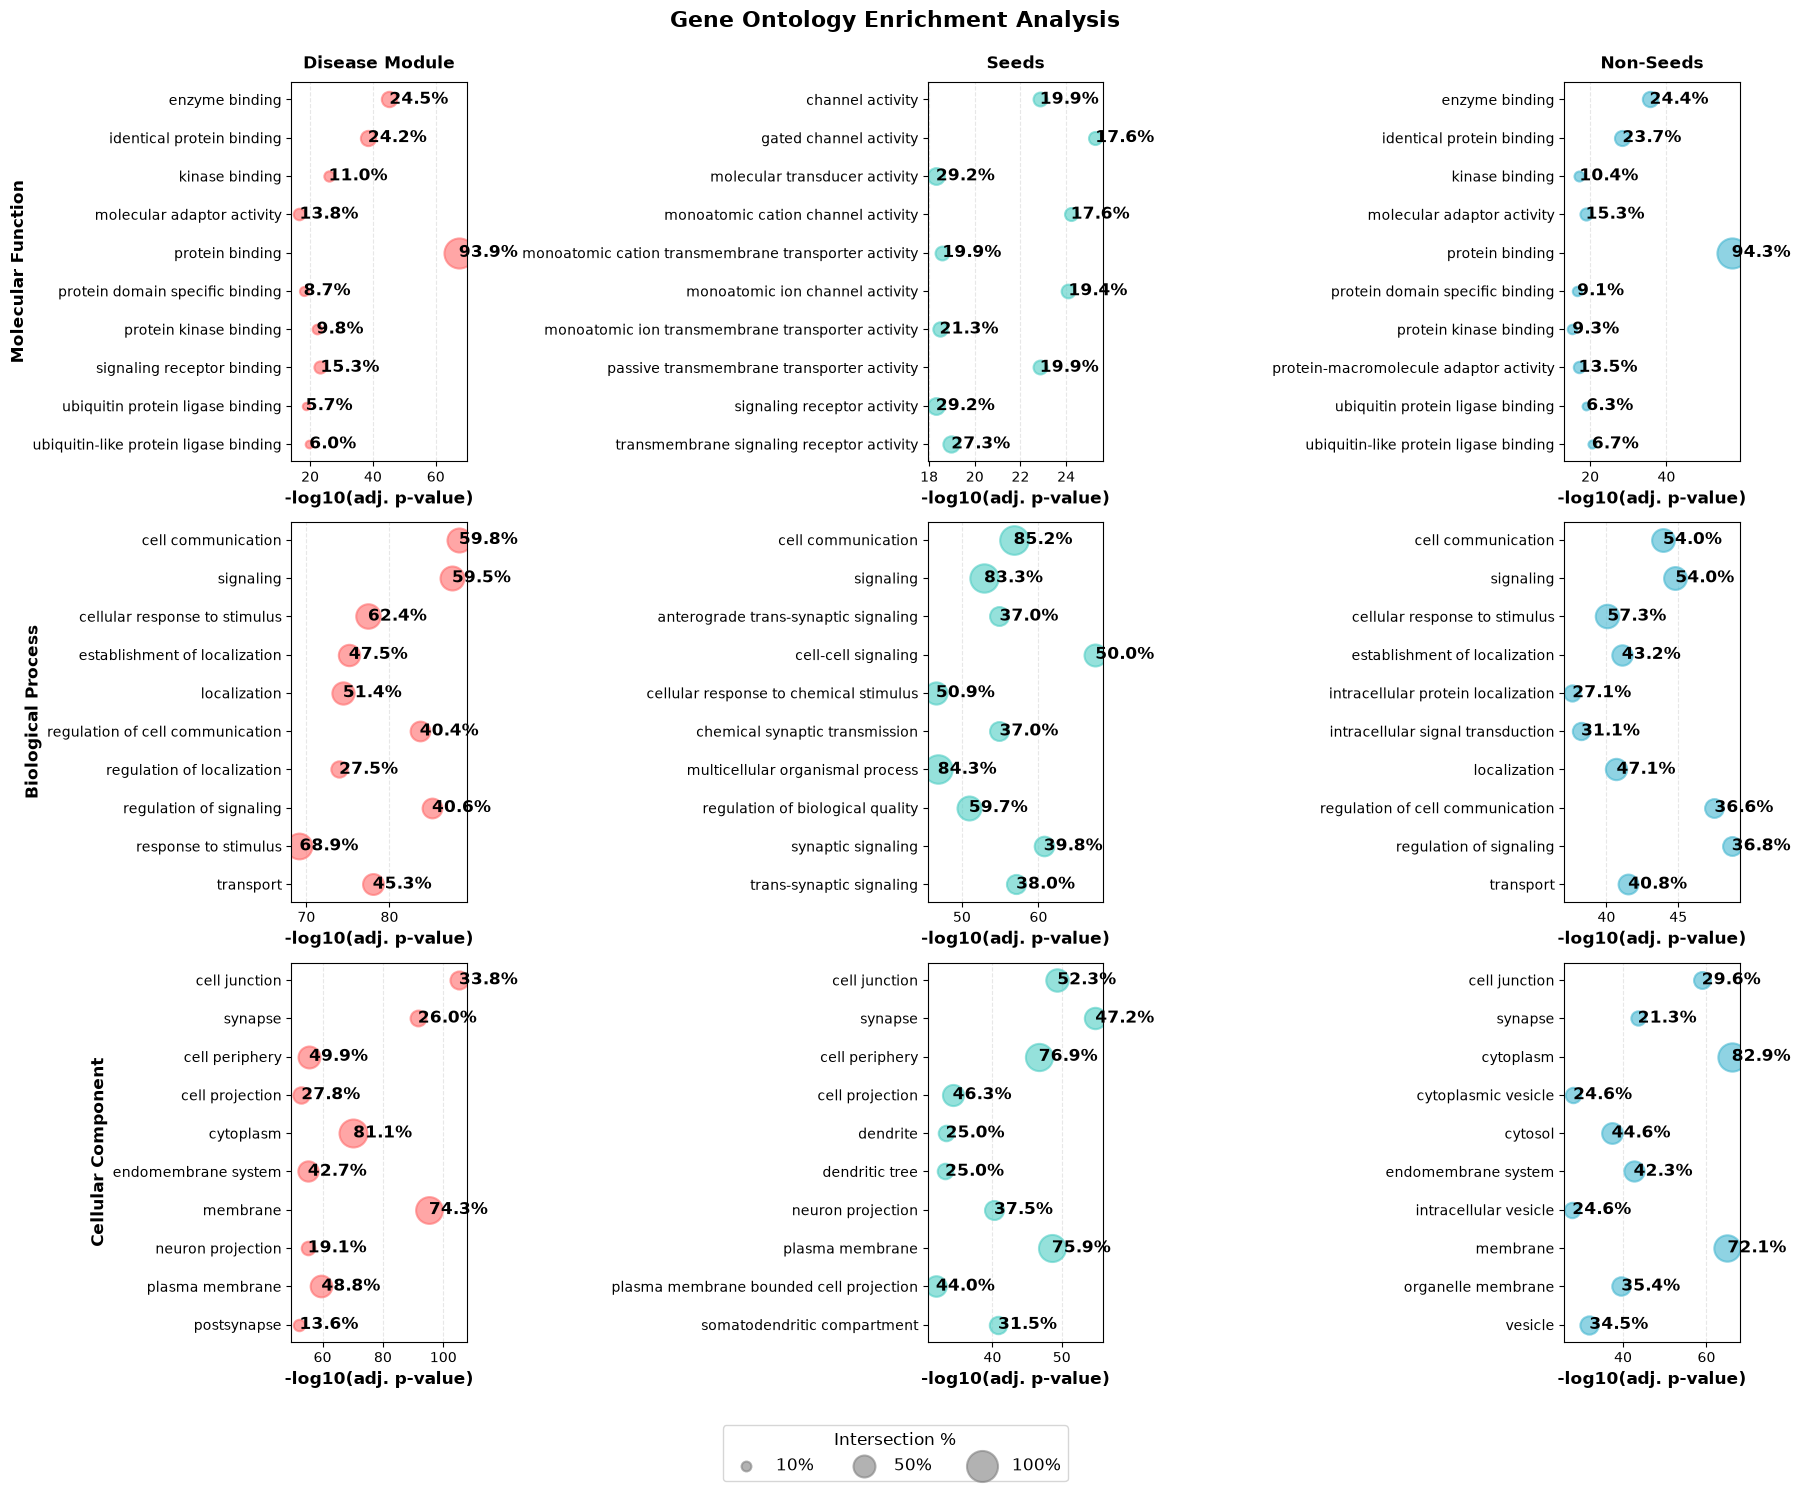

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Read the three CSV files
disease_module_df = pd.read_csv('dm_multiplex_gprofiler.csv')
seeds_df = pd.read_csv('seeds_multiplex_gprofiler.csv')
non_seeds_df = pd.read_csv('nonseeds_multiplex_gprofiler.csv')

# Extract GO category from source column
def extract_go_category(source):
    if 'GO:MF' in source:
        return 'GO:MF'
    elif 'GO:BP' in source:
        return 'GO:BP'
    elif 'GO:CC' in source:
        return 'GO:CC'
    return None

# Map GO categories to full names
go_names = {
    'GO:MF': 'Molecular Function',
    'GO:BP': 'Biological Process',
    'GO:CC': 'Cellular Component'
}

# Define colors for each source
colors = {
    'Disease Module': '#FF6B6B',
    'Seeds': '#4ECDC4',
    'Non-Seeds': '#45B7D1'
}

# Function to consolidate duplicates
def consolidate_duplicates(df):
    df = df.copy()
    df['go_category'] = df['source'].apply(extract_go_category)
    
    # Group by GO category and term_name, keeping the row with best p-value
    df = df.loc[df.groupby(['go_category', 'term_name'])['adjusted_p_value'].idxmin()]
    
    return df

# Consolidate duplicates in all dataframes
disease_module_df = consolidate_duplicates(disease_module_df)
seeds_df = consolidate_duplicates(seeds_df)
non_seeds_df = consolidate_duplicates(non_seeds_df)

# Calculate percentage for each dataframe
disease_module_df['intersection_percentage'] = (disease_module_df['intersection_size'] / disease_module_df['query_size'] * 100)
seeds_df['intersection_percentage'] = (seeds_df['intersection_size'] / seeds_df['query_size'] * 100)
non_seeds_df['intersection_percentage'] = (non_seeds_df['intersection_size'] / non_seeds_df['query_size'] * 100)

# Create figure with 3x3 grid (3 GO categories x 3 sources)
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle('Gene Ontology Enrichment Analysis', fontsize=16, fontweight='bold', y=0.995)

# Process each combination
go_categories = ['GO:MF', 'GO:BP', 'GO:CC']
sources = [('Disease Module', disease_module_df), ('Seeds', seeds_df), ('Non-Seeds', non_seeds_df)]

# For each GO category, determine the unified ordering across all sources
unified_ordering = {}

for go_cat in go_categories:
    all_terms_by_source = {}
    
    # Collect all top 10 terms from each source for this GO category
    for source_name, source_df in sources:
        source_df_copy = source_df.copy()
        source_df_copy['go_category'] = source_df_copy['source'].apply(extract_go_category)
        cat_data = source_df_copy[source_df_copy['go_category'] == go_cat].copy()
        
        if len(cat_data) > 0:
            cat_data = cat_data.nsmallest(10, 'adjusted_p_value')
            all_terms_by_source[source_name] = set(cat_data['term_name'].tolist())
        else:
            all_terms_by_source[source_name] = set()
    
    # Find common terms (present in all three sources)
    common_terms = all_terms_by_source['Disease Module'].intersection(
        all_terms_by_source['Seeds']).intersection(
        all_terms_by_source['Non-Seeds'])
    
    # Find all unique terms
    all_unique_terms = set()
    for terms in all_terms_by_source.values():
        all_unique_terms.update(terms)
    
    # Find non-common terms
    non_common_terms = all_unique_terms - common_terms
    
    # Sort both alphabetically and combine (common first, then non-common)
    ordered_terms = sorted(list(common_terms)) + sorted(list(non_common_terms))
    
    unified_ordering[go_cat] = ordered_terms

# Now plot with unified ordering
for row_idx, go_cat in enumerate(go_categories):
    for col_idx, (source_name, source_df) in enumerate(sources):
        ax = axes[row_idx, col_idx]
        
        # Extract GO category
        source_df = source_df.copy()
        source_df['go_category'] = source_df['source'].apply(extract_go_category)
        
        # Filter data for this GO category
        cat_data = source_df[source_df['go_category'] == go_cat].copy()
        
        if len(cat_data) == 0:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
            ax.set_xticks([])
            ax.set_yticks([])
            continue
        
        # Sort by adjusted p-value and take top 10
        cat_data = cat_data.nsmallest(10, 'adjusted_p_value')
        
        # Reorder according to unified ordering
        ordered_terms = [term for term in unified_ordering[go_cat] if term in cat_data['term_name'].values]
        cat_data = cat_data.set_index('term_name').loc[ordered_terms].reset_index()
        
        # Reverse the dataframe so common terms appear at top visually
        cat_data = cat_data.iloc[::-1].reset_index(drop=True)
        
        # Create bubble plot
        y_pos = np.arange(len(cat_data))
        sizes = cat_data['intersection_percentage'] * 5  # Scale for visibility
        
        # Plot points
        for i, (idx, row) in enumerate(cat_data.iterrows()):
            ax.scatter(
                row['negative_log10_of_adjusted_p_value'],
                i,
                s=sizes.iloc[i],
                alpha=0.6,
                color=colors[source_name],
                linewidth=1.5,
                zorder=2
            )
            
            # Add intersection percentage text inside bubble
            ax.text(
                row['negative_log10_of_adjusted_p_value'],
                i,
                f"{row['intersection_percentage']:.1f}%",
                ha='left',
                va='center',
                fontweight='bold',
                fontsize=12,
                color='black',
                zorder=4
            )
        
        # Set labels and formatting
        ax.set_yticks(y_pos)
        ax.set_yticklabels(cat_data['term_name'], fontsize=10)
        ax.set_xlabel('-log10(adj. p-value)', fontsize=12, fontweight='bold')
        
        # Add titles
        if row_idx == 0:
            ax.set_title(source_name, fontsize=12, fontweight='bold', pad=10)
        if col_idx == 0:
            ax.set_ylabel(go_names[go_cat], fontsize=12, fontweight='bold')
        
        ax.grid(axis='x', alpha=0.3, linestyle='--')
        ax.set_axisbelow(True)

# Add size legend
legend_percentages = [10, 50, 100]
legend_bubbles = []
for pct in legend_percentages:
    legend_bubbles.append(plt.scatter([], [], s=pct*5, c='gray', alpha=0.6, linewidth=1.5))

fig.legend(legend_bubbles, [f'{pct}%' for pct in legend_percentages], 
          scatterpoints=1, title='Intersection %', 
          loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=3, 
          frameon=True, fontsize=12, title_fontsize=12)

plt.tight_layout()
plt.savefig('enrichment_analysis_grid.png', dpi=300, bbox_inches='tight')
plt.show()